# Student Stress: DAGs, BIC comparison, and causal effects (DoWhy)

**Outcome:** `stress_level` (0 = low, 1 = medium, 2 = high)  
**Causes:** `study_load`, `noise_level`, `living_conditions`, `academic_performance`, `future_career_concerns`

In [17]:
# !pip install dowhy statsmodels
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import statsmodels.api as sm
from dowhy import CausalModel, gcm
import warnings
warnings.filterwarnings('ignore')

## 1. Load data

In [ ]:
stress = pd.read_csv('StressLevelDataset.csv')

CAUSES = ['study_load', 'noise_level', 'living_conditions',
          'academic_performance', 'future_career_concerns']
OUTCOME = 'stress_level'

print(stress.shape)
stress[CAUSES + [OUTCOME]].head()

(1100, 21)


,study_load,noise_level,living_conditions,academic_performance,future_career_concerns,stress_level
0,2,2,3,3,3,1
1,4,3,1,1,5,2
2,3,2,2,2,2,1
3,4,4,2,2,4,2
4,3,3,2,4,2,1


## 2. Candidate DAGs

DAG1 and DAG2 are OG original. DAG3 and DAG4 are alternates for further comparisons.

In [19]:
dags = {
    # --- My DAGs ---
    'DAG1': [
        ('safety', 'stress_level'),
        ('study_load', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG2': [
        ('safety', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    # --- Additional alternatives ---
    'DAG3_academic_pathway': [
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
        ('future_career_concerns', 'stress_level'),
        ('study_load', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG4_combined': [
        ('safety', 'stress_level'),
        ('mental_health_history', 'stress_level'),
        ('study_load', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('living_conditions', 'academic_performance'),
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
    ],
}

# Each DAG contains ONLY the variables in its edges - no floating nodes
graphs = {name: nx.DiGraph(edges) for name, edges in dags.items()}
for name, g in graphs.items():
    assert nx.is_directed_acyclic_graph(g), name

all_nodes = sorted(set().union(*[g.nodes for g in graphs.values()]))
data = stress[all_nodes].copy()
print('Nodes:', all_nodes)


Nodes: ['academic_performance', 'future_career_concerns', 'living_conditions', 'mental_health_history', 'noise_level', 'safety', 'stress_level', 'study_load']


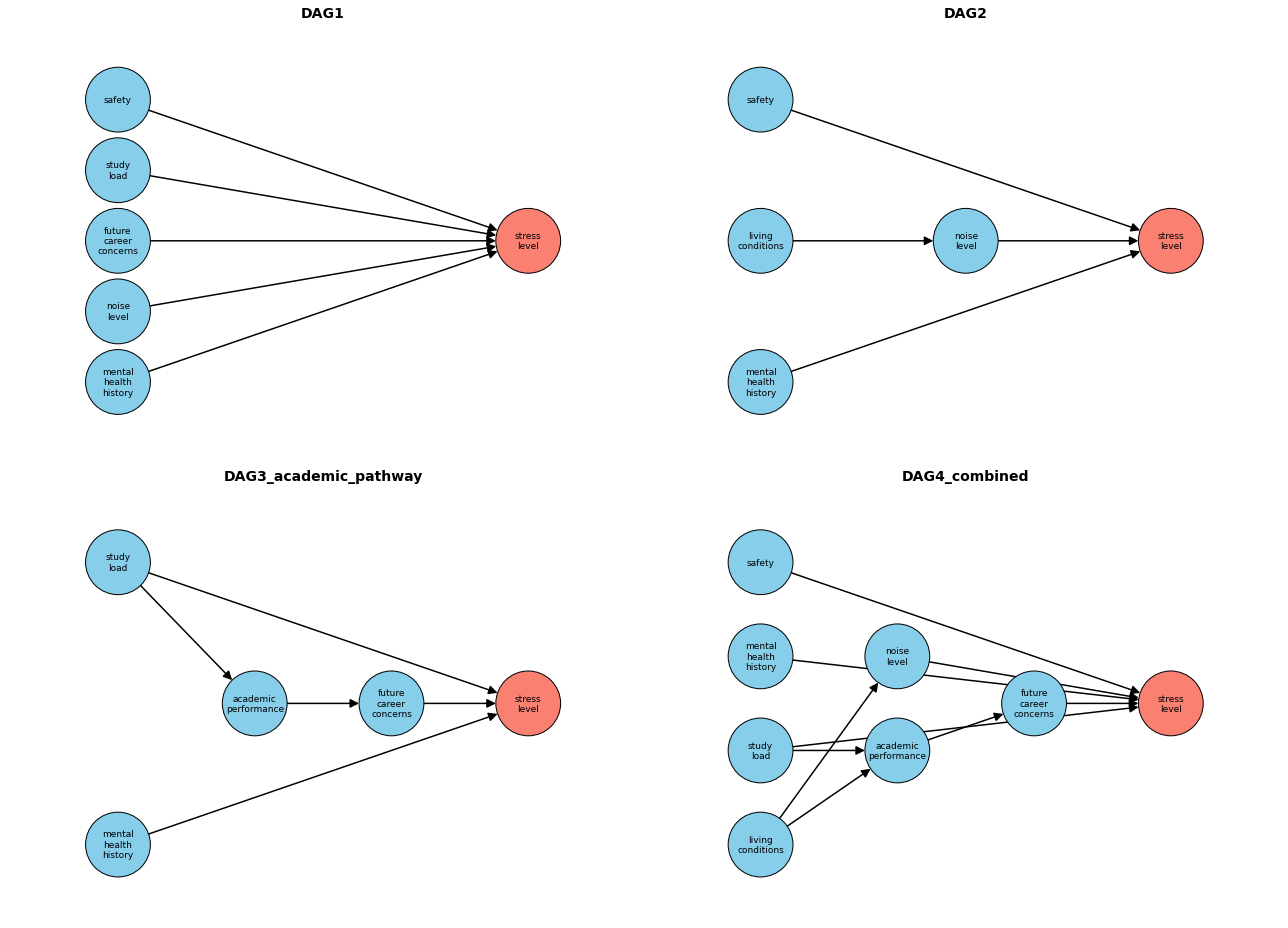

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for ax, (name, g) in zip(axes.ravel(), graphs.items()):
    # layer = length of longest path from a root node (works in any networkx version)
    for n in nx.topological_sort(g):
        preds = list(g.predecessors(n))
        g.nodes[n]['layer'] = 0 if not preds else max(g.nodes[p]['layer'] for p in preds) + 1
    pos = nx.multipartite_layout(g, subset_key='layer')
    colors = ['salmon' if n == OUTCOME else 'skyblue' for n in g]
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=4200, node_color=colors, edgecolors='black')
    nx.draw_networkx_labels(g, pos, ax=ax, labels={n: n.replace('_', '\n') for n in g}, font_size=9)
    nx.draw_networkx_edges(g, pos, ax=ax, node_size=4200, arrowstyle='-|>', arrowsize=18, width=1.5)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.margins(0.2)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Compare DAGs with BIC

A DAG's likelihood factorises into each node given its parents, so DAG BIC = sum of BIC(node ~ parents).  
BIC = −2·logL + k·ln(n). **Lower is better**; ΔBIC > 10 is very strong evidence for the better DAG.

In [21]:
def node_bic(df, node, parents):
    y = df[node].astype(float)
    X = sm.add_constant(df[parents].astype(float), has_constant='add') if parents \
        else np.ones((len(df), 1))
    return sm.OLS(y, X).fit().bic

def dag_bic(df, g):
    # Nodes in the DAG: scored given their parents.
    # Variables not in this DAG: scored as independent, so every DAG is scored on the same data.
    in_dag = sum(node_bic(df, n, list(g.predecessors(n))) for n in g.nodes)
    not_in_dag = sum(node_bic(df, n, []) for n in all_nodes if n not in g)
    return in_dag + not_in_dag

bic_table = pd.DataFrame({
    'DAG': list(graphs),
    'edges': [g.number_of_edges() for g in graphs.values()],
    'BIC': [dag_bic(data, g) for g in graphs.values()],
}).sort_values('BIC').reset_index(drop=True)
bic_table['delta_BIC'] = bic_table['BIC'] - bic_table['BIC'].min()
print(bic_table.to_string(index=False))

best = bic_table.loc[0, 'DAG']
best_graph = graphs[best]
print('\nBest DAG:', best)
print('Edges:', list(best_graph.edges()))

                  DAG  edges          BIC   delta_BIC
        DAG4_combined      9 24298.884434    0.000000
DAG3_academic_pathway      5 24946.442761  647.558327
                 DAG2      4 25568.815541 1269.931107
                 DAG1      5 25615.237184 1316.352750

Best DAG: DAG4_combined
Edges: [('safety', 'stress_level'), ('mental_health_history', 'stress_level'), ('study_load', 'stress_level'), ('study_load', 'academic_performance'), ('noise_level', 'stress_level'), ('future_career_concerns', 'stress_level'), ('living_conditions', 'noise_level'), ('living_conditions', 'academic_performance'), ('academic_performance', 'future_career_concerns')]


## 4. Is each causal effect identified? (DoWhy)

In [22]:
estimands = {}
for cause in CAUSES:
    if cause not in best_graph or not nx.has_path(best_graph, cause, OUTCOME):
        print(f'\n========== {cause} -> {OUTCOME} ==========')
        print(f'No directed path from {cause} to {OUTCOME} in {best}: '
              'the DAG assumes no causal effect, so there is nothing to identify.')
        continue
    model = CausalModel(data=data, graph=best_graph, treatment=cause, outcome=OUTCOME)
    estimand = model.identify_effect()
    estimands[cause] = (model, estimand)
    print(f'\n========== {cause} -> {OUTCOME} ==========')
    print(estimand)


========== study_load -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                      
─────────────(E[stressₗₑᵥₑₗ])
d[study_load]                
Estimand assumption 1, Unconfoundedness: If U→{study_load} and U→stress_level then P(stress_level|study_load,,U) = P(stress_level|study_load,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!


========== noise_level -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                                         
─────────────(E[stress_level|living_conditions])
d[noiseₗₑᵥₑₗ]                                   
Estimand assumption 1, Unconfoundedness: If U→{noise_level} and U→stress_level then P(stress_level|noise_level,living_conditions,U) = P(stress_level|noise_level,living

## 5. Causal impact of each cause (DoWhy)

Effect = change in `stress_level` per 1-unit increase in the cause (total effect, backdoor linear regression).

In [23]:
rows = []
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression',
                                test_significance=True)
    p = est.test_stat_significance()['p_value']
    rows.append({'cause': cause,
                 'adjustment_set': estimand.get_backdoor_variables(),
                 'causal_effect': round(est.value, 4),
                 'p_value': float(np.ravel(p)[0])})
effects = pd.DataFrame(rows).sort_values('causal_effect', key=abs, ascending=False)
print(effects.to_string(index=False))

                 cause                  adjustment_set  causal_effect      p_value
  academic_performance [living_conditions, study_load]        -0.1646 2.960387e-20
     living_conditions                              []        -0.1642 8.496613e-12
future_career_concerns          [academic_performance]         0.1465 1.548783e-07
            study_load                              []         0.1451 1.485283e-13
           noise_level             [living_conditions]         0.1226 1.535679e-16


### Robustness: placebo refuter (effect should drop to ~0)

In [24]:
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression')
    ref = model.refute_estimate(estimand, est, method_name='placebo_treatment_refuter',
                                placebo_type='permute', num_simulations=20)
    print(f'{cause:24s} estimate={est.value:.4f}  placebo={ref.new_effect:.4f}')

study_load               estimate=0.1451  placebo=0.0002
noise_level              estimate=0.1226  placebo=-0.0007
living_conditions        estimate=-0.1642  placebo=-0.0068
academic_performance     estimate=-0.1646  placebo=0.0028
future_career_concerns   estimate=0.1465  placebo=-0.0002


### Optional: GCM fit + graph falsification for the best DAG (slow)

Fitting causal mechanism of node academic_performance: 100%|██████████| 8/8 [00:01<00:00,  4.70it/s]  
Test permutations of given graph: 100%|██████████| 50/50 [00:38<00:00,  1.30it/s]


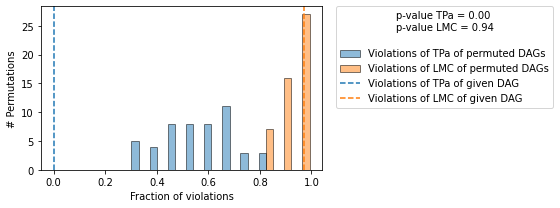

Evaluated the performance of the causal mechanisms and the invertibility assumption of the causal mechanisms and the overall average KL divergence between generated and observed distribution and the graph structure. The results are as follows:

==== Evaluation of Causal Mechanisms ====
The used evaluation metrics are:
- KL divergence (only for root-nodes): Evaluates the divergence between the generated and the observed distribution.
- Mean Squared Error (MSE): Evaluates the average squared differences between the observed values and the conditional expectation of the causal mechanisms.
- Normalized MSE (NMSE): The MSE normalized by the standard deviation for better comparison.
- R2 coefficient: Indicates how much variance is explained by the conditional expectations of the mechanisms. Note, however, that this can be misleading for nonlinear relationships.
- F1 score (only for categorical non-root nodes): The harmonic mean of the precision and recall indicating the goodness of the under

In [25]:
gcm.util.general.set_random_seed(0)
scm = gcm.StructuralCausalModel(best_graph)
gcm.auto.assign_causal_mechanisms(scm, data)
gcm.fit(scm, data)
print(gcm.evaluate_causal_model(scm, data, compare_mechanism_baselines=True))